# EQR Experiment D: Parallel Quotient + Consistency Loss

**Architecture:** EQR (Equivariant Quotient-Residual)

**Key Innovation:** Combined quotient_loss + consistency_loss from Phase 1 (parallel)

## Training Protocol:
- **Phase 1 (1000 epochs):** L = L_quotient + λ·L_consistency (BOTH from start)
- **Phase 2 (1000 epochs):** L = L_geodesic_residual (h frozen)
- **Phase 3 (1000 epochs):** L = L_quotient + λ·L_consistency (joint fine-tuning)

In [1]:
!mkdir /kaggle/working/choir-checkpoint
!cp -r /kaggle/input/datasets/devilenralph/eqrv01/*.pt /kaggle/working/choir-checkpoint

## Cell 1: Install Dependencies

In [2]:
import os
import subprocess
import sys

try:
    import torch_geometric
except ImportError:
    _whl = "/kaggle/input/datasets/tanvirliaquatuday/torch-geometric/tg/torch_geometric-2.7.0-py3-none-any.whl"
    _links = "/kaggle/input/datasets/tanvirliaquatuday/torch-geometric"
    if os.path.exists(_whl):
        subprocess.check_call(
            [
                sys.executable,
                "-m",
                "pip",
                "install",
                "--no-index",
                f"--find-links={_links}",
                _whl,
            ]
        )
    else:
        # Offline dataset not attached — fall back to PyPI
        subprocess.check_call(
            [sys.executable, "-m", "pip", "install", "torch_geometric"]
        )

import os

os.makedirs("/kaggle/working/output_dir", exist_ok=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.7/63.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 21.4 MB/s eta 0:00:00


## Cell 2: Imports

In [3]:
import random
from itertools import permutations, product

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch_geometric.transforms as TG
from torch.utils.data import DataLoader, Dataset
from torch_geometric.data import Data

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


Device: cuda


## Cell 3: Set Random Seed

In [4]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

## Cell 4: Utilities — Random Rotation & Octahedral Group

In [5]:
def random_rotation_matrix(batch_size=1):
    """Sample uniformly from SO(3) via unit quaternions."""
    u1, u2, u3 = torch.rand(3, batch_size)
    q0 = torch.sqrt(1 - u1) * torch.sin(2 * np.pi * u2)
    q1 = torch.sqrt(1 - u1) * torch.cos(2 * np.pi * u2)
    q2 = torch.sqrt(u1) * torch.sin(2 * np.pi * u3)
    q3 = torch.sqrt(u1) * torch.cos(2 * np.pi * u3)
    R = (
        torch.stack(
            [
                1 - 2 * (q2**2 + q3**2),
                2 * (q1 * q2 - q0 * q3),
                2 * (q1 * q3 + q0 * q2),
                2 * (q1 * q2 + q0 * q3),
                1 - 2 * (q1**2 + q3**2),
                2 * (q2 * q3 - q0 * q1),
                2 * (q1 * q3 - q0 * q2),
                2 * (q2 * q3 + q0 * q1),
                1 - 2 * (q1**2 + q2**2),
            ],
            dim=0,
        )
        .reshape(3, 3, batch_size)
        .permute(2, 0, 1)
    )
    return R


def generate_octahedral_group():
    """24 rotational symmetries of the cube."""
    matrices = []
    for perm in permutations([0, 1, 2]):
        for signs in product([-1, 1], repeat=3):
            R = torch.zeros(3, 3)
            for i in range(3):
                R[i, perm[i]] = float(signs[i])
            if torch.det(R) > 0:
                matrices.append(R)
    O_group = torch.stack(matrices)
    assert O_group.shape[0] == 24
    return O_group


OCTAHEDRAL_GROUP = generate_octahedral_group()
print(f"Octahedral group: {OCTAHEDRAL_GROUP.shape[0]} elements")


Octahedral group: 24 elements


## Cell 5: Data Loading & Processing

In [6]:
download_path = "/kaggle/input/datasets/mafruhaislamaishi/shapenet/02691156"
processed_dir = "/kaggle/working/output_dir"
MAX_SAMPLES = None


def custom_read_obj(file_path):
    pos = []
    faces = []
    with open(file_path, "r") as f:
        for line in f:
            components = line.strip().split()
            if not components:
                continue
            if components[0] == "v":
                pos.append([float(x) for x in components[1:4]])
            elif components[0] == "f":
                indices = [int(c.split("/")[0]) - 1 for c in components[1:]]
                for i in range(1, len(indices) - 1):
                    faces.append([indices[0], indices[i], indices[i + 1]])
    if not pos:
        return Data(pos=torch.empty((0, 3)), face=torch.empty((2, 0)))
    pos_tensor = torch.tensor(pos, dtype=torch.float)
    if faces:
        face_tensor = torch.tensor(faces, dtype=torch.long).t().contiguous()
    else:
        face_tensor = torch.empty((3, 0), dtype=torch.long)
    return Data(pos=pos_tensor, face=face_tensor)


def process_shapenet_mesh(
    data_folder, output_folder=None, num_points=2048, max_samples=float("inf")
):
    sampler = TG.SamplePoints(num=num_points, include_normals=False)
    processed_count = 0
    errors = []
    ret = []
    print(f"Scanning {data_folder} for models (max {max_samples} samples)...")
    for root, _, files in os.walk(data_folder):
        if processed_count >= max_samples:
            break
        for file in files:
            if processed_count >= max_samples:
                break
            if file == "model_normalized.obj":
                file_path = os.path.join(root, file)
                path_parts = os.path.normpath(file_path).split(os.sep)
                try:
                    if "models" in path_parts:
                        models_index = path_parts.index("models")
                        model_id = path_parts[models_index - 1]
                    else:
                        model_id = f"model_{processed_count}"
                    data = custom_read_obj(file_path)
                    if data.pos.shape[0] < 50:
                        errors.append((file_path, "Too few vertices"))
                        continue
                    data.face = data.face.long()
                    sampled_data = sampler(data)
                    point_cloud = sampled_data.pos
                    point_cloud = point_cloud - point_cloud.mean(dim=0, keepdim=True)
                    if output_folder:
                        output_path = os.path.join(output_folder, f"{model_id}.pt")
                        torch.save(point_cloud, output_path)
                    ret.append(point_cloud)
                    processed_count += 1
                except Exception as e:
                    errors.append((file_path, str(e)))
    print(f"Processed {processed_count} models. Errors: {len(errors)}")
    return ret


# Check if already processed
existing = (
    [f for f in os.listdir(processed_dir) if f.endswith(".pt")]
    if os.path.exists(processed_dir)
    else []
)
if len(existing) < 10:
    max_s = MAX_SAMPLES if MAX_SAMPLES else float("inf")
    process_shapenet_mesh(
        download_path, processed_dir, num_points=2048, max_samples=max_s
    )
else:
    print(f"Using {len(existing)} existing processed files")


class ShapeNetPointCloudDataset(Dataset):
    def __init__(self, processed_dir, num_points=1024, max_samples=None):
        self.samples = []
        self.cat_to_idx = {}
        for f in sorted(os.listdir(processed_dir)):
            if f.endswith(".pt"):
                self.samples.append((os.path.join(processed_dir, f), 0))
        if max_samples:
            self.samples = self.samples[:max_samples]
        self.num_points = num_points

    def __len__(self):
        return len(self.samples)

    def _sample_points(self, pc):
        n = pc.shape[0]
        if pc.dim() == 2 and pc.shape[1] >= 6:
            pc = pc[:, :3]
        if n >= self.num_points:
            idx = torch.randperm(n)[: self.num_points]
        else:
            idx = torch.randint(0, n, (self.num_points,))
        pts = pc[idx]
        return pts - pts.mean(0, keepdim=True)

    def __getitem__(self, idx):
        file_path, cat = self.samples[idx]
        pc = torch.load(file_path, weights_only=True)
        pc = self._sample_points(pc)
        R = random_rotation_matrix(1).squeeze(0)
        pc_rot = pc @ R
        return pc_rot, cat, R


class SiameseDataset(Dataset):
    """Returns pairs of different instances for consistency training."""

    def __init__(self, base_dataset):
        self.base_dataset = base_dataset
        self.indices = list(range(len(base_dataset)))

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):
        pc1, label1, R1 = self.base_dataset[idx]
        N = len(self.indices)
        idx2 = np.random.randint(0, N)
        if idx2 == idx:
            idx2 = (idx2 + 1) % N
        pc2, label2, R2 = self.base_dataset[idx2]
        return pc1, pc2, R1, R2, label1

Scanning /kaggle/input/datasets/mafruhaislamaishi/shapenet/02691156 for models (max inf samples)...
Processed 4037 models. Errors: 8


## Cell 7: VNN Layers (Deng et al., ICCV 2021)

In [7]:
EPS = 1e-6

class VNLinear(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(VNLinear, self).__init__()
        self.map_to_feat = nn.Linear(in_channels, out_channels, bias=False)

    def forward(self, x):
        x_out = self.map_to_feat(x.transpose(1,-1)).transpose(1,-1)
        return x_out


class VNLeakyReLU(nn.Module):
    def __init__(self, in_channels, share_nonlinearity=False, negative_slope=0.2):
        super(VNLeakyReLU, self).__init__()
        if share_nonlinearity:
            self.map_to_dir = nn.Linear(in_channels, 1, bias=False)
        else:
            self.map_to_dir = nn.Linear(in_channels, in_channels, bias=False)
        self.negative_slope = negative_slope

    def forward(self, x):
        d = self.map_to_dir(x.transpose(1,-1)).transpose(1,-1)
        dotprod = (x*d).sum(2, keepdim=True)
        mask = (dotprod >= 0).float()
        d_norm_sq = (d*d).sum(2, keepdim=True)
        x_out = self.negative_slope * x + (1-self.negative_slope) * (mask*x + (1-mask)*(x-(dotprod/(d_norm_sq+EPS))*d))
        return x_out


class VNBatchNorm(nn.Module):
    def __init__(self, num_features, dim):
        super(VNBatchNorm, self).__init__()
        self.dim = dim
        if dim == 3 or dim == 4:
            self.bn = nn.BatchNorm1d(num_features)
        elif dim == 5:
            self.bn = nn.BatchNorm2d(num_features)

    def forward(self, x):
        norm = torch.norm(x, dim=2) + EPS
        norm_bn = self.bn(norm)
        norm = norm.unsqueeze(2)
        norm_bn = norm_bn.unsqueeze(2)
        x = x / norm * norm_bn
        return x


class VNLinearLeakyReLU(nn.Module):
    def __init__(self, in_channels, out_channels, dim=5, share_nonlinearity=False, negative_slope=0.2):
        super(VNLinearLeakyReLU, self).__init__()
        self.dim = dim
        self.negative_slope = negative_slope
        self.map_to_feat = nn.Linear(in_channels, out_channels, bias=False)
        self.batchnorm = VNBatchNorm(out_channels, dim=dim)
        if share_nonlinearity:
            self.map_to_dir = nn.Linear(in_channels, 1, bias=False)
        else:
            self.map_to_dir = nn.Linear(in_channels, out_channels, bias=False)

    def forward(self, x):
        p = self.map_to_feat(x.transpose(1,-1)).transpose(1,-1)
        p = self.batchnorm(p)
        d = self.map_to_dir(x.transpose(1,-1)).transpose(1,-1)
        dotprod = (p*d).sum(2, keepdims=True)
        mask = (dotprod >= 0).float()
        d_norm_sq = (d*d).sum(2, keepdims=True)
        x_out = self.negative_slope * p + (1-self.negative_slope) * (mask*p + (1-mask)*(p-(dotprod/(d_norm_sq+EPS))*d))
        return x_out


class VNMaxPool(nn.Module):
    def __init__(self, in_channels):
        super(VNMaxPool, self).__init__()
        self.map_to_dir = nn.Linear(in_channels, in_channels, bias=False)

    def forward(self, x):
        d = self.map_to_dir(x.transpose(1,-1)).transpose(1,-1)
        dotprod = (x*d).sum(2, keepdims=True)
        idx = dotprod.max(dim=-1, keepdim=False)[1]
        index_tuple = torch.meshgrid([torch.arange(j) for j in x.size()[:-1]], indexing='ij') + (idx,)
        x_max = x[index_tuple]
        return x_max


def mean_pool(x, dim=-1, keepdim=False):
    return x.mean(dim=dim, keepdim=keepdim)

## Cell 8: Stage 1 — Equivariant Orientation Hypothesizer

In [8]:
class VNEncoder(nn.Module):
    """SO(3)-equivariant encoder φ: R^{N×3} → R^{C×3×N}"""
    def __init__(self, in_channels=1, hidden_channels=64, out_channels=128):
        super().__init__()
        self.conv1 = VNLinearLeakyReLU(in_channels, hidden_channels, dim=4)
        self.conv2 = VNLinearLeakyReLU(hidden_channels, hidden_channels, dim=4)
        self.conv3 = VNLinearLeakyReLU(hidden_channels, out_channels, dim=4)

    def forward(self, x):
        x = x.permute(0, 2, 1).unsqueeze(1)
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        return x


class VNInvariantLayer(nn.Module):
    """Produces SO(3)-equivariant frame V: R^{C×3×N} → R^{3×3×N}"""
    def __init__(self, in_channels):
        super().__init__()
        self.vn1 = VNLinearLeakyReLU(in_channels, in_channels // 2, dim=4)
        self.vn2 = VNLinearLeakyReLU(in_channels // 2, in_channels // 4, dim=4)
        self.vn_lin = VNLinear(in_channels // 4, 3)

    def forward(self, x):
        x = self.vn1(x)
        x = self.vn2(x)
        V = self.vn_lin(x)
        return V


class RotationPredictor(nn.Module):
    """SO(3)-equivariant: reduces C→2, mean-pools, Gram-Schmidt → SO(3)"""
    def __init__(self, in_channels):
        super().__init__()
        self.vn_lin = VNLinear(in_channels, 2)

    def forward(self, x):
        basis = self.vn_lin(x)
        basis = basis.mean(dim=-1)
        v1 = basis[:, 0, :]
        v2 = basis[:, 1, :]
        e1 = F.normalize(v1, dim=-1)
        dot = (v2 * e1).sum(dim=-1, keepdim=True)
        e2_proj = v2 - dot * e1
        e2 = F.normalize(e2_proj, dim=-1, eps=1e-6)
        e3 = torch.cross(e1, e2, dim=-1)
        R = torch.stack([e1, e2, e3], dim=1)
        return R


class OrientationHypothesizer(nn.Module):
    """h = ψ ∘ φ — SO(3)-equivariant"""
    def __init__(self, hidden_channels=64, out_channels=128):
        super().__init__()
        self.encoder = VNEncoder(1, hidden_channels, out_channels)
        self.rotation_predictor = RotationPredictor(out_channels)
        self.inv_layer = VNInvariantLayer(out_channels)

    def forward(self, x):
        equiv_feat = self.encoder(x)
        R_hyp = self.rotation_predictor(equiv_feat)
        V = self.inv_layer(equiv_feat)
        return R_hyp, equiv_feat, V

## Cell 9: Stage 2 — Invariant Residual Predictor

In [9]:
class InvariantFeatureExtractor(nn.Module):
    """φ(PR)(VR)^T = φ(P)V^T — SO(3)-invariant via inner product trick"""
    def __init__(self, in_channels, frame_channels=3):
        super().__init__()
        self.in_channels = in_channels
        self.frame_channels = frame_channels

    def forward(self, phi_feat, V_feat):
        inv_feat = torch.einsum('bcin,bdin->bcdn', phi_feat, V_feat)
        B, C, D, N = inv_feat.shape
        return inv_feat.permute(0, 3, 1, 2).reshape(B, N, C * D)


class PointTransformerLayer(nn.Module):
    """Point Transformer layer (Zhao et al., 2021)."""
    def __init__(self, in_dim, out_dim=None, num_neighbors=16):
        super().__init__()
        out_dim = out_dim or in_dim
        self.num_neighbors = num_neighbors
        self.phi = nn.Linear(in_dim, out_dim)
        self.psi = nn.Linear(in_dim, out_dim)
        self.alpha = nn.Linear(in_dim, out_dim)
        self.pos_enc = nn.Sequential(
            nn.Linear(3, out_dim), nn.ReLU(), nn.Linear(out_dim, out_dim))
        self.gamma = nn.Sequential(
            nn.Linear(out_dim, out_dim), nn.ReLU(), nn.Linear(out_dim, out_dim))
        self.out_dim = out_dim

    def forward(self, x, pos):
        B, N, D = x.shape
        k = min(self.num_neighbors, N)
        with torch.no_grad():
            dists = torch.cdist(pos, pos)
            _, knn_idx = dists.topk(k, dim=-1, largest=False)
        batch_idx = torch.arange(B, device=x.device).view(B, 1, 1).expand(B, N, k)
        x_neighbors = x[batch_idx, knn_idx]
        pos_neighbors = pos[batch_idx, knn_idx]
        phi_x = self.phi(x).unsqueeze(2)
        psi_x = self.psi(x_neighbors)
        alpha_x = self.alpha(x_neighbors)
        pos_diff = pos.unsqueeze(2) - pos_neighbors
        delta = self.pos_enc(pos_diff)
        attn_input = phi_x - psi_x + delta
        attn_weights = self.gamma(attn_input)
        attn_weights = F.softmax(attn_weights, dim=2)
        out = (attn_weights * (alpha_x + delta)).sum(dim=2)
        return out


class PointTransformerBlock(nn.Module):
    def __init__(self, dim, num_neighbors=16):
        super().__init__()
        self.linear_in = nn.Linear(dim, dim)
        self.pt_layer = PointTransformerLayer(dim, dim, num_neighbors)
        self.linear_out = nn.Linear(dim, dim)

    def forward(self, x, pos):
        identity = x
        x = self.linear_in(x)
        x = self.pt_layer(x, pos)
        x = self.linear_out(x)
        x = x + identity
        return x


class ResidualPredictor(nn.Module):
    """SO(3)-invariant continuous residual predictor: 6D → Gram-Schmidt → SO(3)"""
    def __init__(self, in_channels=128, hidden_dim=256, inv_feat_channels=3, num_neighbors=16):
        super().__init__()
        self.inv_feat_extractor = InvariantFeatureExtractor(in_channels, inv_feat_channels)
        inv_feat_dim = in_channels * inv_feat_channels
        self.point_embed = nn.Sequential(
            nn.Linear(3, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))
        self.feat_embed = nn.Sequential(
            nn.Linear(inv_feat_dim, hidden_dim), nn.ReLU(), nn.Linear(hidden_dim, hidden_dim))
        self.pt_block1 = PointTransformerBlock(hidden_dim, num_neighbors)
        self.pt_block2 = PointTransformerBlock(hidden_dim, num_neighbors)
        self.out_mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim), nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim // 2), nn.ReLU(),
            nn.Linear(hidden_dim // 2, 6))

    def forward(self, canon_pc, phi_feat, V_feat):
        inv_feat = self.inv_feat_extractor(phi_feat, V_feat)
        point_emb = self.point_embed(canon_pc)
        feat_emb = self.feat_embed(inv_feat)
        combined = point_emb + feat_emb
        combined = self.pt_block1(combined, canon_pc)
        combined = self.pt_block2(combined, canon_pc)
        pooled = combined.mean(dim=1)
        out = self.out_mlp(pooled)
        v1 = out[:, :3]
        v2 = out[:, 3:]
        e1 = F.normalize(v1, dim=-1)
        e2_proj = v2 - (v2 * e1).sum(dim=-1, keepdim=True) * e1
        e2 = F.normalize(e2_proj, dim=-1, eps=1e-6)
        e3 = torch.cross(e1, e2, dim=-1)
        R_residual = torch.stack([e1, e2, e3], dim=1)
        return R_residual

## Cell 10: EQR Model

In [10]:
class EQR(nn.Module):
    """Equivariant Quotient-Residual Pipeline.

    f(PR) = g(z) · h(PR)
    Equivariance: f(PR) = f(P) · R (exact, by construction)

    Key: Phase 1 uses PARALLEL quotient + consistency loss
    """
    def __init__(self, hidden_channels=64, out_channels=128, residual_hidden_dim=256, num_neighbors=16):
        super().__init__()
        self.hypothesizer = OrientationHypothesizer(hidden_channels, out_channels)
        self.residual_predictor = ResidualPredictor(
            out_channels, residual_hidden_dim,
            inv_feat_channels=3, num_neighbors=num_neighbors)

    def forward(self, x):
        R_hyp, equiv_feat, V_feat = self.hypothesizer(x)
        canon_pc = x @ R_hyp.transpose(-1, -2)
        R_res = self.residual_predictor(canon_pc, equiv_feat, V_feat)
        R_final = R_res @ R_hyp
        return R_final, R_hyp, R_res, equiv_feat

    def forward_hypothesis_only(self, x):
        R_hyp, equiv_feat, V_feat = self.hypothesizer(x)
        return R_hyp, equiv_feat, V_feat

    def canonicalize(self, x):
        R_final, _, _, _ = self.forward(x)
        return x @ R_final.transpose(-1, -2)

## Cell 11: Loss Functions & Evaluation Metrics

In [11]:
def consistency_loss(R_pred1, R_pred2, R1, R2):
    """Siamese consistency: ‖R'₁ᵀR'₂ - R₁ᵀR₂‖²_F"""
    target = R1.transpose(-1, -2) @ R2
    pred_rel = R_pred1.transpose(-1, -2) @ R_pred2
    diff = pred_rel - target
    return (diff ** 2).sum(dim=(1, 2)).mean()


def quotient_loss(R_pred, R_gt, O_group):
    """Octahedral quotient: min_{Q∈O} ‖R_pred - R_gt·Q‖²_F"""
    B = R_pred.shape[0]
    R_gt_Q = R_gt.unsqueeze(1) @ O_group.unsqueeze(0)
    diff = R_pred.unsqueeze(1) - R_gt_Q
    frob_sq = (diff ** 2).sum(dim=(-2, -1))
    min_frob_sq = frob_sq.min(dim=1)[0]
    return min_frob_sq.mean()


def find_closest_octahedral(R_pred, R_gt, O_group):
    B = R_pred.shape[0]
    R_gt_Q = R_gt.unsqueeze(1) @ O_group.unsqueeze(0)
    diff = R_pred.unsqueeze(1) - R_gt_Q
    frob_sq = (diff ** 2).sum(dim=(-2, -1))
    idx = frob_sq.argmin(dim=1)
    Q_star = O_group[idx]
    return Q_star, idx


def geodesic_loss(R_pred, R_target):
    R_diff = R_pred.transpose(-1, -2) @ R_target
    trace = R_diff.diagonal(dim1=-2, dim2=-1).sum(-1)
    trace = torch.clamp(trace, -1.0 + 1e-7, 3.0 - 1e-7)
    angle = torch.acos((trace - 1.0) / 2.0)
    return (angle ** 2).mean()


def residual_loss(R_res, R_hyp, R_gt, O_group):
    with torch.no_grad():
        Q_star, _ = find_closest_octahedral(R_hyp, R_gt, O_group)
        target = Q_star.transpose(-1, -2)
    return geodesic_loss(R_res, target)


def full_pipeline_loss(R_final, R_gt, O_group):
    return quotient_loss(R_final, R_gt, O_group)


def rotation_angle(R1, R2):
    R_diff = R1.transpose(-1, -2) @ R2
    trace = R_diff.diagonal(dim1=-2, dim2=-1).sum(-1)
    trace = torch.clamp(trace, -1.0 + 1e-7, 3.0 - 1e-7)
    angle = torch.acos((trace - 1.0) / 2.0)
    return angle


def chordal_l2_mean(rotations):
    Ce = rotations.sum(dim=0)
    U, _, Vt = torch.linalg.svd(Ce)
    det = torch.det(U @ Vt)
    if det < 0:
        U[:, -1] *= -1
    S = U @ Vt
    return S


def compute_stability(model, pc, num_rotations=10):
    model.eval()
    device_m = next(model.parameters()).device
    pc = pc.to(device_m)
    with torch.no_grad():
        rotations = random_rotation_matrix(num_rotations).to(device_m)
        net_rotations = []
        for i in range(num_rotations):
            R = rotations[i]
            pc_rot = pc @ R
            R_pred, _, _, _ = model(pc_rot.unsqueeze(0))
            R_pred = R_pred[0]
            R_net = R @ R_pred.transpose(-1, -2)
            net_rotations.append(R_net)
        net_rotations = torch.stack(net_rotations)
        R_mean = chordal_l2_mean(net_rotations)
        angles = rotation_angle(
            net_rotations,
            R_mean.unsqueeze(0).expand(num_rotations, -1, -1))
        stability = torch.sqrt((angles ** 2).mean()).item() * 180.0 / np.pi
    return stability


def compute_consistency(model, dataset, num_samples=50):
    model.eval()
    device_m = next(model.parameters()).device
    orientations = []
    with torch.no_grad():
        for i in range(min(num_samples, len(dataset))):
            if isinstance(dataset, torch.utils.data.Subset):
                base_ds = dataset.dataset
                actual_idx = dataset.indices[i]
            else:
                base_ds = dataset
                actual_idx = i
            file_path, cat = base_ds.samples[actual_idx]
            pc = torch.load(file_path, weights_only=True)
            pc = base_ds._sample_points(pc)
            pc = pc - pc.mean(dim=0, keepdim=True)
            pc = pc.to(device_m)
            R_pred, _, _, _ = model(pc.unsqueeze(0))
            R_pred = R_pred[0].cpu()
            orientations.append(R_pred)
    if len(orientations) < 2:
        return 0.0
    orientations = torch.stack(orientations)
    R_mean = chordal_l2_mean(orientations)
    angles = rotation_angle(
        orientations,
        R_mean.unsqueeze(0).expand(len(orientations), -1, -1))
    consistency = torch.sqrt((angles ** 2).mean()).item() * 180.0 / np.pi
    return consistency

## Cell 12: Checkpointing

In [12]:
CHECKPOINT_INPUT_DIR = "/kaggle/working/choir-checkpoint"
CHECKPOINT_SAVE_DIR  = "/kaggle/working"


def save_checkpoint(model, optimizer, scheduler, epoch, loss, phase, is_best=False):
    state = {
        'epoch': epoch, 'phase': phase,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scheduler_state_dict': scheduler.state_dict(),
        'loss': loss,
    }
    current_path = os.path.join(CHECKPOINT_SAVE_DIR, f'eqr_d_phase{phase}_current.pt')
    torch.save(state, current_path)
    if is_best:
        best_path = os.path.join(CHECKPOINT_SAVE_DIR, f'eqr_d_phase{phase}_best.pt')
        torch.save(state, best_path)
        print(f"  [Checkpoint] Phase {phase} best saved at epoch {epoch}, loss={loss:.6f}")


def load_checkpoint(model, optimizer=None, scheduler=None, phase=1):
    for fname in [f'eqr_d_phase{phase}_current.pt', f'eqr_d_phase{phase}_best.pt']:
        path = os.path.join(CHECKPOINT_INPUT_DIR, fname)
        if os.path.exists(path):
            print(f"  [Checkpoint] Loading from {path}")
            state = torch.load(path, map_location=device, weights_only=True)
            model.load_state_dict(state['model_state_dict'])
            if optimizer is not None:
                optimizer.load_state_dict(state['optimizer_state_dict'])
            if scheduler is not None:
                scheduler.load_state_dict(state['scheduler_state_dict'])
            start_epoch = state['epoch'] + 1
            best_loss = state['loss']
            print(f"  [Checkpoint] Phase {phase} resuming from epoch {start_epoch}")
            return start_epoch, best_loss
    print(f"  [Checkpoint] No Phase {phase} checkpoint found, starting fresh.")
    return 0, float('inf')


def load_best_checkpoint(model, phase):
    for fname in [f'eqr_d_phase{phase}_best.pt', f'eqr_d_phase{phase}_current.pt']:
        path = os.path.join(CHECKPOINT_SAVE_DIR, fname)
        if not os.path.exists(path):
            path = os.path.join(CHECKPOINT_INPUT_DIR, fname)
        if os.path.exists(path):
            state = torch.load(path, map_location=device, weights_only=True)
            model.load_state_dict(state['model_state_dict'])
            print(f"  [Checkpoint] Loaded Phase {phase} best from {path}")
            return True
    return False

## Cell 13: Training Functions — Experiment D (Parallel)

In [13]:
def train_phase1_parallel(model, loader, siamese_loader, optimizer, scheduler,
                           O_group, epochs, lambda_c=1.0):
    """Phase 1: quotient + consistency IN PARALLEL.
    Key innovation: both losses active from epoch 1."""
    model.train()
    O_dev = O_group.to(device)
    start_epoch, best_loss = load_checkpoint(model, optimizer, scheduler, phase=1)

    # Freeze residual predictor
    for p in model.residual_predictor.parameters():
        p.requires_grad = False

    for epoch in range(start_epoch, epochs):
        model.train()
        total_loss = 0
        siamese_iter = iter(siamese_loader)

        for pc, _, R_gt in loader:
            pc, R_gt = pc.to(device), R_gt.to(device)
            optimizer.zero_grad()

            # --- Quotient loss (per-instance accuracy) ---
            _, R_hyp, _, _ = model(pc)
            loss_q = quotient_loss(R_hyp, R_gt, O_dev)

            # --- Consistency loss (cross-instance alignment) ---
            try:
                pc1, pc2, R1, R2, _ = next(siamese_iter)
            except StopIteration:
                siamese_iter = iter(siamese_loader)
                pc1, pc2, R1, R2, _ = next(siamese_iter)
            pc1, pc2 = pc1.to(device), pc2.to(device)
            R1, R2 = R1.to(device), R2.to(device)
            Rp1, _, _, _ = model(pc1)
            Rp2, _, _, _ = model(pc2)
            loss_c = consistency_loss(Rp1, Rp2, R1, R2)

            loss = loss_q + lambda_c * loss_c
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.hypothesizer.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        scheduler.step()
        avg_loss = total_loss / len(loader)
        is_best = avg_loss < best_loss
        if is_best:
            best_loss = avg_loss
        save_checkpoint(model, optimizer, scheduler, epoch, best_loss, phase=1, is_best=is_best)

        if (epoch + 1) % 50 == 0 or is_best:
            print(f"  Phase1 Epoch {epoch+1}/{epochs}  loss={avg_loss:.6f}  best={best_loss:.6f}  "
                  f"LR={scheduler.get_last_lr()[0]:.6f}")

    for p in model.residual_predictor.parameters():
        p.requires_grad = True


def train_phase2_residual(model, loader, optimizer, scheduler, O_group, epochs):
    """Phase 2: geodesic residual loss, hypothesizer frozen."""
    model.train()
    O_dev = O_group.to(device)
    start_epoch, best_loss = load_checkpoint(model, optimizer, scheduler, phase=2)

    for p in model.hypothesizer.parameters():
        p.requires_grad = False

    for epoch in range(start_epoch, epochs):
        model.train()
        total_loss = 0
        for pc, _, R_gt in loader:
            pc, R_gt = pc.to(device), R_gt.to(device)
            optimizer.zero_grad()
            _, R_hyp, R_res, _ = model(pc)
            loss = residual_loss(R_res, R_hyp, R_gt, O_dev)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.residual_predictor.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        scheduler.step()
        avg_loss = total_loss / len(loader)
        is_best = avg_loss < best_loss
        if is_best:
            best_loss = avg_loss
        save_checkpoint(model, optimizer, scheduler, epoch, best_loss, phase=2, is_best=is_best)

        if (epoch + 1) % 50 == 0 or is_best:
            print(f"  Phase2 Epoch {epoch+1}/{epochs}  loss={avg_loss:.6f}  best={best_loss:.6f}  "
                  f"LR={scheduler.get_last_lr()[0]:.6f}")

    for p in model.hypothesizer.parameters():
        p.requires_grad = True


def train_phase3_joint(model, loader, siamese_loader, optimizer, scheduler,
                        O_group, epochs, lambda_c=1.0, lambda_res=1.0):
    """Phase 3: joint fine-tuning with quotient + consistency + residual."""
    model.train()
    O_dev = O_group.to(device)
    start_epoch, best_loss = load_checkpoint(model, optimizer, scheduler, phase=3)

    for epoch in range(start_epoch, epochs):
        model.train()
        total_loss = 0
        siamese_iter = iter(siamese_loader)

        for pc, _, R_gt in loader:
            pc, R_gt = pc.to(device), R_gt.to(device)
            optimizer.zero_grad()

            R_final, R_hyp, R_res, _ = model(pc)

            # Quotient losses
            loss_q = quotient_loss(R_hyp, R_gt, O_dev)
            loss_full = full_pipeline_loss(R_final, R_gt, O_dev)
            loss_res = residual_loss(R_res, R_hyp, R_gt, O_dev)

            # Consistency loss (Siamese)
            try:
                pc1, pc2, R1, R2, _ = next(siamese_iter)
            except StopIteration:
                siamese_iter = iter(siamese_loader)
                pc1, pc2, R1, R2, _ = next(siamese_iter)
            pc1, pc2 = pc1.to(device), pc2.to(device)
            R1, R2 = R1.to(device), R2.to(device)
            Rp1, _, _, _ = model(pc1)
            Rp2, _, _, _ = model(pc2)
            loss_c = consistency_loss(Rp1, Rp2, R1, R2)

            loss = loss_q + loss_full + lambda_res * loss_res + lambda_c * loss_c
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()

        scheduler.step()
        avg_loss = total_loss / len(loader)
        is_best = avg_loss < best_loss
        if is_best:
            best_loss = avg_loss
        save_checkpoint(model, optimizer, scheduler, epoch, best_loss, phase=3, is_best=is_best)

        if (epoch + 1) % 50 == 0 or is_best:
            print(f"  Phase3 Epoch {epoch+1}/{epochs}  loss={avg_loss:.6f}  best={best_loss:.6f}  "
                  f"LR={scheduler.get_last_lr()[0]:.6f}")

## Cell 14: Run Experiment D — Setup & Configuration

In [14]:
print("=" * 60)
print("EXPERIMENT D: EQR + PARALLEL Quotient + Consistency")
print("=" * 60)

# Hyperparameters
NUM_POINTS = 1024
BATCH_SIZE = 16
PHASE1_EPOCHS = 200
PHASE2_EPOCHS = 200
PHASE3_EPOCHS = 200
PHASE1_LR = 0.001
PHASE2_LR = 0.001
PHASE3_LR = 0.0001
LAMBDA_C = 1.0     # Consistency loss weight
LAMBDA_RES = 1.0   # Residual loss weight in Phase 3

# Dataset
base_dataset = ShapeNetPointCloudDataset(processed_dir, num_points=NUM_POINTS, max_samples=None)
dataset_size = len(base_dataset)
train_size = int(0.8 * dataset_size)
test_size = dataset_size - train_size

train_base, test_base = torch.utils.data.random_split(
    base_dataset, [train_size, test_size],
    generator=torch.Generator().manual_seed(42))

siamese_train = SiameseDataset(train_base)
train_loader = DataLoader(train_base, batch_size=BATCH_SIZE, shuffle=True)
siamese_loader = DataLoader(siamese_train, batch_size=BATCH_SIZE, shuffle=True)

# Model
model = EQR(
    hidden_channels=64,
    out_channels=64,
    residual_hidden_dim=128,
    num_neighbors=16
).to(device)

print(f"Dataset: {len(base_dataset)} total, {train_size} train, {test_size} test")
print(f"Points per cloud: {NUM_POINTS}")
print(f"Device: {device}")
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"  Hypothesizer:       {sum(p.numel() for p in model.hypothesizer.parameters()):,}")
print(f"  Residual predictor: {sum(p.numel() for p in model.residual_predictor.parameters()):,}")
print()

EXPERIMENT D: EQR + PARALLEL Quotient + Consistency
Dataset: 4037 total, 3229 train, 808 test
Points per cloud: 1024
Device: cuda
Parameters: 370,902
  Hypothesizer:       22,288
  Residual predictor: 348,614



## Cell 15: Phase 1 Training — Quotient + Consistency (PARALLEL)

In [15]:
print("-" * 60)
print(f"PHASE 1: Quotient + Consistency (PARALLEL)")
print(f"  L = L_quotient + {LAMBDA_C} * L_consistency")
print(f"  Epochs: {PHASE1_EPOCHS}, LR: {PHASE1_LR}")
print("-" * 60)

optimizer1 = torch.optim.Adam(model.hypothesizer.parameters(), lr=PHASE1_LR)
scheduler1 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer1, T_max=PHASE1_EPOCHS)
train_phase1_parallel(model, train_loader, siamese_loader, optimizer1, scheduler1,
                       OCTAHEDRAL_GROUP, PHASE1_EPOCHS, lambda_c=LAMBDA_C)

------------------------------------------------------------
PHASE 1: Quotient + Consistency (PARALLEL)
  L = L_quotient + 1.0 * L_consistency
  Epochs: 200, LR: 0.001
------------------------------------------------------------
  [Checkpoint] Loading from /kaggle/working/choir-checkpoint/eqr_d_phase1_current.pt
  [Checkpoint] Phase 1 resuming from epoch 100
  Phase1 Epoch 150/200  loss=4.674897  best=4.450395  LR=0.000500
  Phase1 Epoch 200/200  loss=4.790533  best=4.450395  LR=0.001000


## Cell 16: Phase 2 Training — Geodesic Residual (h frozen)

In [16]:
print()
print("-" * 60)
print(f"PHASE 2: Geodesic Residual (h frozen)")
print(f"  Epochs: {PHASE2_EPOCHS}, LR: {PHASE2_LR}")
print("-" * 60)

load_best_checkpoint(model, phase=1)
optimizer2 = torch.optim.Adam(model.residual_predictor.parameters(), lr=PHASE2_LR)
scheduler2 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer2, T_max=PHASE2_EPOCHS)
train_phase2_residual(model, train_loader, optimizer2, scheduler2,
                       OCTAHEDRAL_GROUP, PHASE2_EPOCHS)


------------------------------------------------------------
PHASE 2: Geodesic Residual (h frozen)
  Epochs: 200, LR: 0.001
------------------------------------------------------------
  [Checkpoint] Loaded Phase 1 best from /kaggle/working/choir-checkpoint/eqr_d_phase1_best.pt
  [Checkpoint] Loading from /kaggle/working/choir-checkpoint/eqr_d_phase2_current.pt
  [Checkpoint] Phase 2 resuming from epoch 100
  Phase2 Epoch 150/200  loss=4.732682  best=4.687469  LR=0.000500
  Phase2 Epoch 200/200  loss=4.794995  best=4.687469  LR=0.001000


## Cell 17: Phase 3 Training — Joint Fine-Tuning

In [17]:
print()
print("-" * 60)
print(f"PHASE 3: Joint Fine-Tuning (quotient + consistency + residual)")
print(f"  Epochs: {PHASE3_EPOCHS}, LR: {PHASE3_LR}")
print("-" * 60)

load_best_checkpoint(model, phase=2)
optimizer3 = torch.optim.Adam(model.parameters(), lr=PHASE3_LR)
scheduler3 = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer3, T_max=PHASE3_EPOCHS)
train_phase3_joint(model, train_loader, siamese_loader, optimizer3, scheduler3,
                    OCTAHEDRAL_GROUP, PHASE3_EPOCHS, lambda_c=LAMBDA_C, lambda_res=LAMBDA_RES)

print()
print("=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)


------------------------------------------------------------
PHASE 3: Joint Fine-Tuning (quotient + consistency + residual)
  Epochs: 200, LR: 0.0001
------------------------------------------------------------
  [Checkpoint] Loaded Phase 2 best from /kaggle/working/choir-checkpoint/eqr_d_phase2_best.pt
  [Checkpoint] Loading from /kaggle/working/choir-checkpoint/eqr_d_phase3_current.pt
  [Checkpoint] Phase 3 resuming from epoch 100
  [Checkpoint] Phase 3 best saved at epoch 107, loss=9.969521
  Phase3 Epoch 108/200  loss=9.969521  best=9.969521  LR=0.000002
  Phase3 Epoch 150/200  loss=10.186005  best=9.969521  LR=0.000050
  [Checkpoint] Phase 3 best saved at epoch 179, loss=9.898950
  Phase3 Epoch 180/200  loss=9.898950  best=9.898950  LR=0.000090
  [Checkpoint] Phase 3 best saved at epoch 180, loss=9.818248
  Phase3 Epoch 181/200  loss=9.818248  best=9.818248  LR=0.000091
  [Checkpoint] Phase 3 best saved at epoch 184, loss=9.739299
  Phase3 Epoch 185/200  loss=9.739299  best=9.739

## Cell 18: Evaluation

In [18]:
print("=" * 60)
print("EVALUATION")
print("=" * 60)

model.eval()
load_best_checkpoint(model, phase=3)

# Stability
stabilities = []
with torch.no_grad():
    for i in range(min(50, len(test_base))):
        if isinstance(test_base, torch.utils.data.Subset):
            file_path, _ = base_dataset.samples[test_base.indices[i]]
        else:
            file_path, _ = base_dataset.samples[i]
        pc = torch.load(file_path, weights_only=True)
        pc = base_dataset._sample_points(pc)
        pc = pc - pc.mean(0, keepdim=True)
        stab = compute_stability(model, pc.to(device), num_rotations=10)
        stabilities.append(stab)

avg_stability = np.mean(stabilities)

# Consistency
consistency = compute_consistency(model, test_base, num_samples=50)

print(f"\n{'='*60}")
print(f"EXPERIMENT D RESULTS")
print(f"{'='*60}")
print(f"  Stability:   {avg_stability:.4f}° (lower = better, 0° = perfect)")
print(f"  Consistency: {consistency:.4f}° (lower = better)")
print(f"{'='*60}")

EVALUATION
  [Checkpoint] Loaded Phase 3 best from /kaggle/working/eqr_d_phase3_best.pt

EXPERIMENT D RESULTS
  Stability:   0.0249° (lower = better, 0° = perfect)
  Consistency: 53.6351° (lower = better)


## Cell 19: Inference Visualization

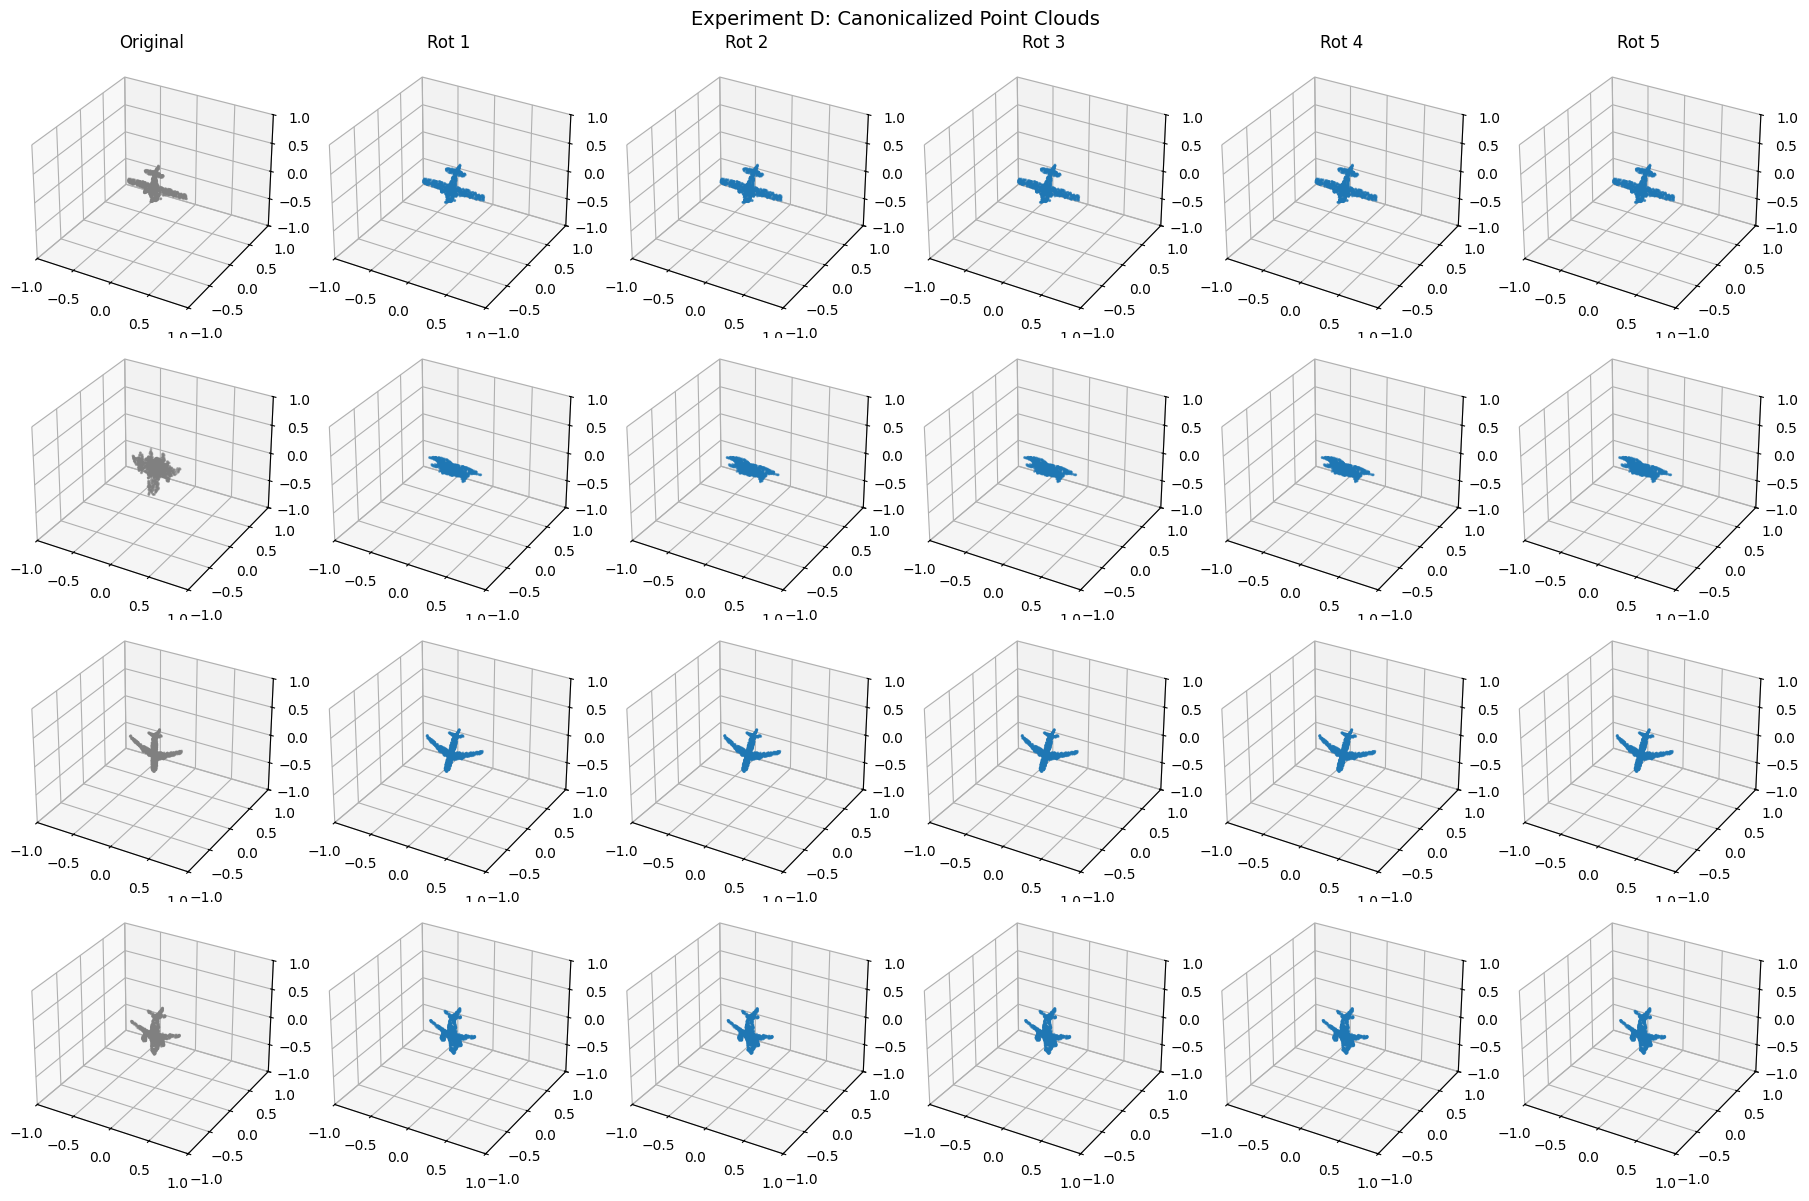

Visualization saved to /kaggle/working/experiment_d_canonicalization.png


In [19]:
import matplotlib.pyplot as plt

model.eval()
num_objects = 4
num_rotations = 5

fig, axes = plt.subplots(num_objects, num_rotations + 1, figsize=(18, 12),
                          subplot_kw={'projection': '3d'})
fig.suptitle("Experiment D: Canonicalized Point Clouds", fontsize=14)

with torch.no_grad():
    for obj_i in range(num_objects):
        if isinstance(test_base, torch.utils.data.Subset):
            file_path, _ = base_dataset.samples[test_base.indices[obj_i]]
        else:
            file_path, _ = base_dataset.samples[obj_i]
        pc = torch.load(file_path, weights_only=True)
        pc = base_dataset._sample_points(pc)
        pc = pc - pc.mean(0, keepdim=True)

        # Original (no rotation)
        ax = axes[obj_i, 0]
        ax.scatter(pc[:, 0], pc[:, 1], pc[:, 2], s=1, c='gray', alpha=0.5)
        ax.set_title("Original" if obj_i == 0 else "")
        ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)

        for rot_i in range(num_rotations):
            R = random_rotation_matrix(1).squeeze(0)
            pc_rot = pc @ R
            canon = model.canonicalize(pc_rot.unsqueeze(0).to(device))[0].cpu().numpy()

            ax = axes[obj_i, rot_i + 1]
            ax.scatter(canon[:, 0], canon[:, 1], canon[:, 2], s=1, alpha=0.5)
            ax.set_title(f"Rot {rot_i+1}" if obj_i == 0 else "")
            ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1)

plt.tight_layout()
plt.savefig("/kaggle/working/experiment_d_canonicalization.png", dpi=150)
plt.show()
print("Visualization saved to /kaggle/working/experiment_d_canonicalization.png")